# Banking Customer Churn Prediction
**Author:** Sreya Peddu · **Data:** fully synthetic (generated with `numpy`, seed 42) · **No real customer or employer data is used.**

This notebook predicts which bank customers are likely to churn so retention efforts can be targeted:
1. Load & clean the synthetic dataset
2. Exploratory analysis of churn drivers by segment
3. Segment analysis in SQL (SQLite)
4. Train & compare Logistic Regression vs Random Forest
5. Key insights and recommended next steps

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys

sns.set_theme(style="whitegrid")
%matplotlib inline

sys.path.insert(0, "../src")
from data_cleaning import clean_customers, basic_quality_report

df = clean_customers(pd.read_csv("../data/customers.csv"))
report = basic_quality_report(df)
print("Quality report:")
for k, v in report.items():
    print(f"  {k}: {v}")
print(f"\nChurn rate: {df['churned'].mean():.2%}")
df.head()

Quality report:
  rows: 10000
  churn_rate: 0.1621
  missing_values: 0
  duplicate_customer_ids: 0

Churn rate: 16.21%


,customer_id,age,tenure_months,balance,num_products,has_credit_card,is_active_member,estimated_salary,geography,gender,churned,tenure_band
0,100000,23,40,5649.18,1,1,0,73844.78,Canada,Male,1,37-60 months
1,100001,65,26,92682.53,1,1,0,76928.83,Canada,Female,0,13-36 months
2,100002,58,62,60856.77,2,0,1,137688.90,USA,Female,0,61+ months
3,100003,45,80,49972.04,1,1,1,91361.35,USA,Female,0,61+ months
4,100004,44,31,65159.68,2,1,0,103960.97,USA,Female,0,13-36 months


## 1. Exploratory Data Analysis — churn drivers by segment

Business questions:
- Do newer customers churn more than long-tenured ones?
- Does holding more products reduce churn?
- What does the churned vs retained profile look like?

 tenure_band  customers  churn_rate  retention_rate
 0-12 months       1103    0.269266        0.730734
13-36 months       1980    0.223232        0.776768
37-60 months       1977    0.168943        0.831057
  61+ months       4940    0.110931        0.889069


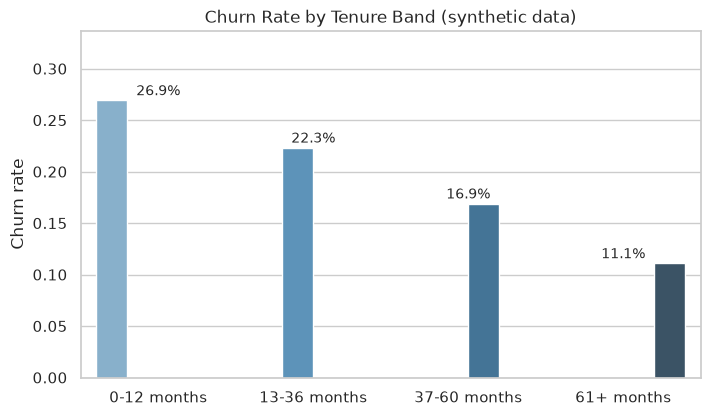

In [2]:
from analysis import churn_rate_by

tenure = churn_rate_by(df, "tenure_band")
tenure = tenure.set_index("tenure_band").loc[
    ["0-12 months", "13-36 months", "37-60 months", "61+ months"]].reset_index()
print(tenure[["tenure_band", "customers", "churn_rate", "retention_rate"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=tenure, x="tenure_band", y="churn_rate", hue="tenure_band",
            palette="Blues_d", legend=False, ax=ax)
ax.set_title("Churn Rate by Tenure Band (synthetic data)")
ax.set_ylabel("Churn rate")
ax.set_xlabel("")
ax.set_ylim(0, tenure["churn_rate"].max() * 1.25)
for i, v in enumerate(tenure["churn_rate"]):
    ax.text(i, v + 0.005, f"{v:.1%}", ha="center", fontsize=10)
plt.show()

 num_products  customers  churn_rate  pct_of_customers
            1       4465    0.199552            0.4465
            2       3562    0.142617            0.3562
            3       1471    0.121006            0.1471
            4        502    0.087649            0.0502


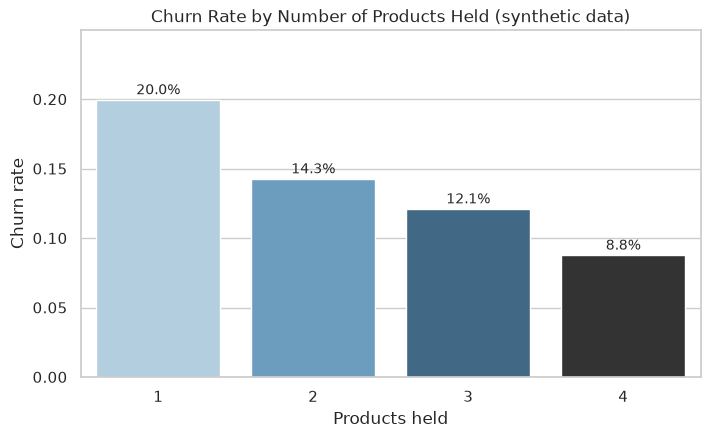

In [3]:
products = churn_rate_by(df, "num_products").sort_values("num_products")
print(products[["num_products", "customers", "churn_rate", "pct_of_customers"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=products, x="num_products", y="churn_rate", hue="num_products",
            palette="Blues_d", legend=False, ax=ax)
ax.set_title("Churn Rate by Number of Products Held (synthetic data)")
ax.set_ylabel("Churn rate")
ax.set_xlabel("Products held")
ax.set_ylim(0, products["churn_rate"].max() * 1.25)
for i, v in enumerate(products["churn_rate"]):
    ax.text(i, v + 0.004, f"{v:.1%}", ha="center", fontsize=10)
plt.show()

In [4]:
from analysis import numeric_summary, at_risk_segment

print("Numeric feature summary by churn status (mean):")
summary = numeric_summary(df)
print(summary.xs("mean", level=1, axis=1).T.to_string())

atr = at_risk_segment(df)
print(f"\nAt-risk segment (inactive, tenure <= 24 mo, 1 product): "
      f"{len(atr):,} customers ({len(atr)/len(df):.1%} of base), "
      f"churn rate {atr['churned'].mean():.1%}")

Numeric feature summary by churn status (mean):
churned                  0          1
age                  48.42      47.53
tenure_months        62.10      46.58
balance           50729.79   47398.15
num_products          1.84       1.61
has_credit_card       0.70       0.69
is_active_member      0.60       0.30
estimated_salary  99939.84  102084.81
churned               0.00       1.00

At-risk segment (inactive, tenure <= 24 mo, 1 product): 430 customers (4.3% of base), churn rate 46.7%


## 2. SQL segment analysis

The same segment questions are answered in SQL (SQLite) — see `../sql/analysis_queries.sql`.
Each query runs against the `customers` table loaded from `data/customers.csv`.

In [5]:
conn = sqlite3.connect(":memory:")
df.drop(columns=["tenure_band"]).to_sql("customers", conn, index=False)
queries = open("../sql/analysis_queries.sql").read()
body = "\n".join(l for l in queries.splitlines() if not l.strip().startswith("--"))
labels = ["Churn rate by tenure band",
          "Churn rate by num_products",
          "Churn rate by geography",
          "Avg balance: churned vs retained"]
for label, q in zip(labels, [s for s in body.split(";") if s.strip()]):
    print(f"--- {label} ---")
    display(pd.read_sql_query(q, conn))
    print()

--- Churn rate by tenure band ---


,tenure_band,customers,churned_customers,churn_rate_pct,retention_rate_pct
0,0-12 months,1103,297,26.93,73.07
1,13-36 months,1980,442,22.32,77.68
2,37-60 months,1977,334,16.89,83.11
3,61+ months,4940,548,11.09,88.91



--- Churn rate by num_products ---


,num_products,customers,churned_customers,churn_rate_pct,pct_of_customers
0,1,4465,891,19.96,44.65
1,2,3562,508,14.26,35.62
2,3,1471,178,12.10,14.71
3,4,502,44,8.76,5.02



--- Churn rate by geography ---


,geography,customers,churned_customers,churn_rate_pct
0,USA,4908,826,16.83
1,UK,3066,484,15.79
2,Canada,2026,311,15.35



--- Avg balance: churned vs retained ---


,segment,customers,avg_balance,avg_tenure_months,avg_num_products,active_member_pct
0,churned,1621,47398.15,46.6,1.61,30.35
1,retained,8379,50729.79,62.1,1.84,59.51


## 3. Modeling — churn classification

- **Target:** `churned` (1/0), base rate ~16% → stratified 75/25 split
- **Features:** 7 numeric + 2 categorical (one-hot); numeric features standardized
- **Models:** Logistic Regression (interpretable baseline) vs Random Forest (non-linear), both `class_weight="balanced"`
- **Metrics:** accuracy, precision, recall, F1, ROC-AUC @ 0.5 threshold + 5-fold CV ROC-AUC

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUM = ["age", "tenure_months", "balance", "num_products",
       "has_credit_card", "is_active_member", "estimated_salary"]
CAT = ["geography", "gender"]
X = df[NUM + CAT]
y = df["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

pre = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
])
models = {
    "Logistic Regression": Pipeline([
        ("preprocess", pre),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))]),
    "Random Forest": Pipeline([
        ("preprocess", pre),
        ("model", RandomForestClassifier(n_estimators=200, max_depth=12,
                                         min_samples_leaf=20, class_weight="balanced",
                                         random_state=42, n_jobs=-1))]),
}

results, probs = {}, {}
rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probs[name] = p
    m = {"accuracy": accuracy_score(y_test, pred),
         "precision": precision_score(y_test, pred, zero_division=0),
         "recall": recall_score(y_test, pred),
         "f1": f1_score(y_test, pred),
         "roc_auc": roc_auc_score(y_test, p)}
    results[name] = m
    rows.append({"model": name, **{k: round(v, 3) for k, v in m.items()}})

display(pd.DataFrame(rows).set_index("model"))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("5-fold stratified CV ROC-AUC (train):")
for name, pipe in models.items():
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"  {name}: mean={s.mean():.3f} std={s.std():.3f}")

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.668,0.285,0.696,0.405,0.726
Random Forest,0.676,0.282,0.647,0.393,0.712


5-fold stratified CV ROC-AUC (train):
  Logistic Regression: mean=0.720 std=0.013


  Random Forest: mean=0.717 std=0.014


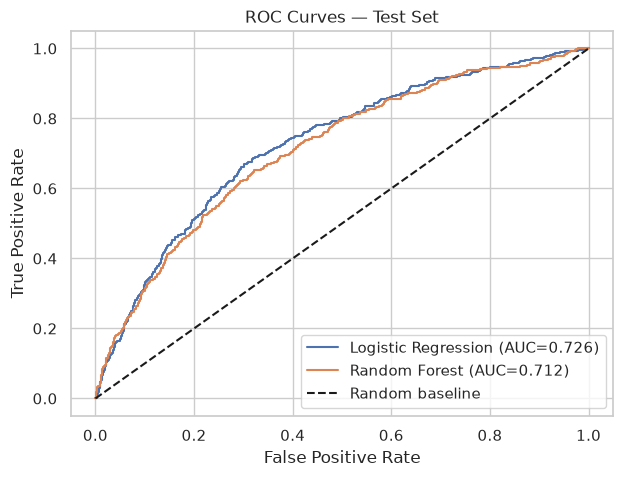

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC={results[name]['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Random baseline")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — Test Set")
ax.legend(loc="lower right")
plt.show()

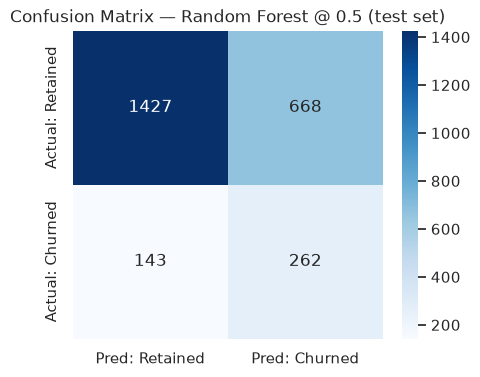

In [8]:
cm = confusion_matrix(y_test, (probs["Random Forest"] >= 0.5).astype(int))
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Pred: Retained", "Pred: Churned"],
            yticklabels=["Actual: Retained", "Actual: Churned"])
ax.set_title("Confusion Matrix — Random Forest @ 0.5 (test set)")
plt.show()

         feature  importance
is_active_member    0.300448
   tenure_months    0.256660
         balance    0.128506
estimated_salary    0.103731
             age    0.086878
    num_products    0.063294
 has_credit_card    0.012094
   geography_USA    0.011438
   gender_Female    0.010665
     gender_Male    0.010426


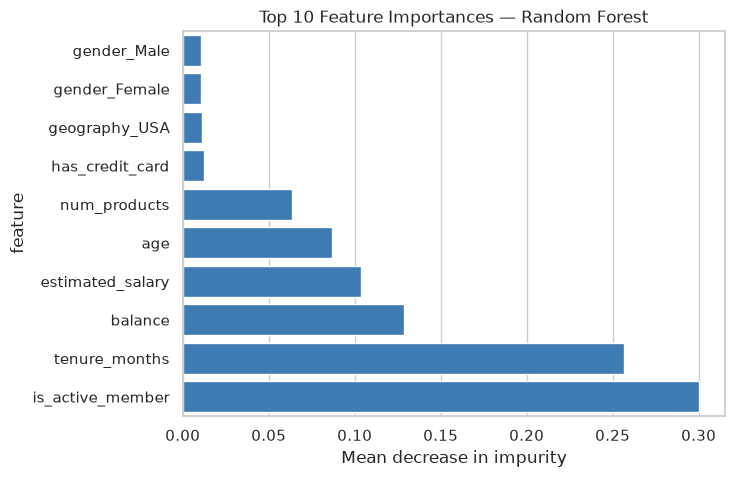

In [9]:
rf = models["Random Forest"]
imp = rf.named_steps["model"].feature_importances_
cat_names = rf.named_steps["preprocess"].named_transformers_["cat"].get_feature_names_out(CAT)
fi = (pd.DataFrame({"feature": NUM + list(cat_names), "importance": imp})
        .sort_values("importance", ascending=False).head(10))
print(fi.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=fi.iloc[::-1], x="importance", y="feature", color="#2a7cc7", ax=ax)
ax.set_title("Top 10 Feature Importances — Random Forest")
ax.set_xlabel("Mean decrease in impurity")
plt.show()

## 4. Key insights

1. **Inactivity is the strongest churn signal.** Churned customers are active members only ~30% of the time vs ~60% for retained customers, and `is_active_member` is the top model feature (importance 0.30).
2. **New customers churn ~2.4× more than long-tenured ones.** The 0–12 month tenure band churns at ~27% vs ~11% for 61+ months — an early-life onboarding/engagement window is the highest-leverage retention target.
3. **Single-product customers are 2.3× more likely to churn** (20.0% vs 8.8% for 4 products), supporting cross-sell as a retention lever.

**Modeling takeaway:** both models separate churners from retained customers well above random (test ROC-AUC ~0.71–0.73). For a cheap retention intervention (e.g., targeted email), lowering the decision threshold to ~0.3–0.4 trades precision for recall — catching ~80–90% of churners.

**Next steps:** calibrate probabilities for campaign sizing, add tenure/activity interaction features, and validate lift with an A/B-tested retention pilot.